# Lecture 9 — Introduction to Streamlit 
## From Charts to Dashboards

> **Dataset:** World Happiness Report 2023

> **Big Book of Dashboards:** Introduction + Chapter 1 — What is a dashboard?

---
## Opening: Model Answer Review

---
## What Is [Streamlit](https://streamlit.io/)?

**Streamlit** is an **open-source Python library** for building **interactive web apps and dashboards** using only Python — no HTML, CSS, or JavaScript required. You write Python code (just like a normal script) and Streamlit automatically generates a web interface with charts, widgets (sliders, buttons, dropdowns), tables, and more. It’s designed especially for **data scientists**, **analysts**, and **machine learning engineers** who want to share insights and tools quickly. 

Key features:

- **Python-centric development:** build full web apps without frontend languages.
- **Interactive widgets:** users can interact with the app in real time.
- **Automatic re-execution:** the app reruns when inputs change, updating the UI instantly.
- **Easy deployment:** publish to Streamlit Community Cloud or other hosting platforms with minimal configuration.

**[Streamlit Sheet Cheet](https://docs.streamlit.io/develop/quick-reference/cheat-sheet)**

Streamlit is not only a teaching or prototyping tool — it is widely used in **industry** for internal analytics tools, decision-support dashboards, and machine-learning applications. For example, in **Snowflake**, a leading cloud data platform, uses Streamlit extensively for **internal dashboards and data tools** across teams. Employees build Streamlit apps to explore metrics, monitor systems, and support business and engineering decisions — without relying on separate frontend teams. Snowflake reports having **hundreds of Streamlit apps** running internally.

---
## What Is a Dashboard?


### What is a dashboard: a visual display of data used to monitor conditions and/or facilitate understanding.

### Two things matter in this definition:

1. It must be visual — numbers in a table are not a dashboard
2. It must have a purpose — monitoring OR understanding. If you cannot say which of these your dashboard does, you do not yet have a dashboard idea, you have a data collection

### Chart vs Dashboard — the key difference

| | Chart | Dashboard |
|---|---|---|
| Answers | One question | Multiple related questions simultaneously |
| Audience | Anyone | A specific person or role |
| Usage | Once, to make a point | Repeatedly, to monitor over time |
| Filters | None to minimal | User-controlled |
| Success measure | Did the audience understand the message? | Does the audience return to use it? |


### 💡 The single-purpose rule

Before any code, write this sentence:

> ❌ *'This dashboard shows the World Happiness data.'* (topic, not purpose)

> ✅ *'This dashboard helps a UN policy analyst see which countries lead on happiness and what factors drive the gap.'* (audience + purpose)

---
## Let's Code Some Examples 💻 

> **HOW TO RUN:** Copy each block into `app.py`, run `streamlit run app.py`.


In [3]:
import streamlit as st
import pandas as pd

In [4]:
df = pd.read_csv('../data/world_happiness_2023.csv')

df.head()

,Country name,Regional indicator,Ladder score,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,Finland,Western Europe,7.804,10.775,0.954,71.9,0.949,0.142,0.179
1,Denmark,Western Europe,7.586,10.933,0.954,72.7,0.931,0.168,0.234
2,Iceland,Western Europe,7.525,10.878,0.983,72.5,0.961,0.260,0.150
3,Israel,Middle East and North Africa,7.473,10.527,0.916,72.4,0.903,0.149,0.826
4,Netherlands,Western Europe,7.464,11.015,0.939,72.4,0.879,0.240,0.296


In [5]:
# ── STEP 1: Minimal working app ──────────────────────────────────────────
import streamlit as st
import pandas as pd


df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']

st.set_page_config(page_title="World Happiness Report", page_icon="🌐")

st.title("World Happiness Dashboard")
st.write(f"Data loaded: {len(df)} countries")


2026-11-25 16:00:54.249 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.249 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.276 
  command:

    streamlit run /Users/pvk/Library/Python/3.14/lib/python/site-packages/ipykernel_launcher.py [ARGUMENTS]
2026-11-25 16:00:54.277 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.277 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.277 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.277 Thread 'MainThread': missing ScriptRunContext! This warning can be igno

In [6]:
# ── STEP 2: Add a chart  ───────────────────────────

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title="World Happiness Report", page_icon="🌐")

df = pd.read_csv('../data/world_happiness_2023.csv')

df.columns = ['Country','Region','Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']

st.title("World Happiness Dashboard")
st.write(f"Data loaded: {len(df)} countries")

# add a bar chart of top 15 countries in Happiness Score
top15 = df.nlargest(15, 'Score').sort_values('Score')
fig = px.bar(top15, x='Score', y='Country', orientation='h',
             labels={'Score': 'Happiness Score (0–10)', 'Country': ''},
             template='plotly_white', title="Happiest 15 Countries in 2023")

fig.update_layout(title_font=dict(family='Arial', size=13, color='slategrey'),
                  xaxis=dict(range=[0, 8.0]))


st.plotly_chart(fig, width='stretch') 


2026-11-25 16:00:54.341 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.343 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.343 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.343 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.343 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.343 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.344 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.432 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [7]:
# ── STEP 3: Sidebar filter + reactive chart ──────────────────────────────

import streamlit as st
import pandas as pd
import plotly.express as px

st.set_page_config(page_title="World Happiness Report", page_icon="🌐")

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']

st.title("World Happiness Dashboard 🌐")

# Add a filter for region and a filter for number of topc countries to show
with st.sidebar:
    st.header("Filters")
    regions = ['All Regions'] + sorted(df['Region'].unique().tolist())
    selected_region = st.selectbox("Region", regions)
    top_n = st.slider("Show top N countries", 5, 20, 10)

# filter data accordingly: 
filtered = df if selected_region == 'All Regions' else df[df['Region'] == selected_region]
top = filtered.nlargest(top_n, 'Score').sort_values('Score')

# create top bar chart
fig = px.bar(top, x='Score', y='Country', orientation='h',
             labels={'Score': 'Happiness Score (0–10)', 'Country': ''},
             template='plotly_white', title=f'Happiest {top_n} Countries in 2023 - {selected_region}')

fig.update_layout(title_font=dict(family='Arial', size=13, color='slategrey'),
                  xaxis=dict(range=[0, 8.0]))


st.plotly_chart(fig, width='stretch', height=600) 

2026-11-25 16:00:54.441 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.444 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.445 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.450 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.452 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.452 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.452 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.453 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

In [8]:
# ── STEP 4: Full dashboard — KPIs + Sidebar Filters + reactive chart ──────────


import streamlit as st
import pandas as pd
import plotly.express as px

# Page configuration, title and data source
st.set_page_config(page_title="World Happiness Report", page_icon="🌐", layout='wide')
st.title("🌍 World Happiness Dashboard")
st.caption("Source: World Happiness Report 2023 | Kaggle")

# Data Ingestion
df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']

# Side bar filters
with st.sidebar:
    st.header("Filters")
    regions = ['All Regions'] + sorted(df['Region'].unique().tolist())
    selected_region = st.selectbox("Region", regions)
    top_n = st.slider("Show top N", 5, 25, 15)
    

# filter data by region and top_n
filtered = df if selected_region == 'All Regions' else df[df['Region'] == selected_region]
top = filtered.nlargest(top_n, 'Score').sort_values('Score')

# KPI row 
col1, col2, col3 = st.columns(3)
col1.metric("Countries", len(filtered))
col2.metric("Avg Score", f"{filtered['Score'].mean():.2f}",
            f"{filtered['Score'].mean()-df['Score'].mean():+.2f} vs global")
col3.metric("Happiest", filtered.nlargest(1,'Score')['Country'].values[0])

st.divider()

# create top bar chart
fig = px.bar(top, x='Score', y='Country', orientation='h',
             labels={'Score': 'Happiness Score (0–10)', 'Country': ''},
             template='plotly_white', title=f'Happiest {top_n} Countries in 2023 - {selected_region}')

fig.update_layout(title_font=dict(family='Arial', size=13, color='slategrey'),
                  xaxis=dict(range=[0, 8.0]))


st.plotly_chart(fig, width='stretch', height=600) 

st.divider()
st.caption("Built with Streamlit + Plotly")


2026-11-25 16:00:54.473 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.474 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.474 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.474 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.475 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.475 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.475 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-25 16:00:54.477 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bar

DeltaGenerator()

---
## Class Exercise 💪 💻

1. Add another chart of your choice to the dashboard that uses a diverging continuous colour scale (something where values go above and below a meaningful midpoint). Label the midpoint in an annotation.

2. Publish your expanded dashboard through you classwork repo.


### My solution

**New chart:** how far each country's happiness score is from the **global average** (a diverging bar chart).

- **Midpoint:** the global average score of all 63 countries. A dashed line marks it, with the annotation *Midpoint = global average*.
- **Diverging colour scale:** red = below the average, blue = above, **neutral grey at the midpoint**. The colour range is symmetric (±max gap), so grey sits exactly at 0.
- It reacts to the **Region** filter, but the midpoint stays the *global* average, so a region's bars show how it compares with the world.

Copy the next block into `app.py` and run `streamlit run app.py`.

In [ ]:
# ── STEP 5: Exercise — add a diverging chart with an annotated midpoint ──────

import streamlit as st
import pandas as pd
import plotly.express as px


# Page configuration, title and data source
st.set_page_config(page_title="World Happiness Report", page_icon="🌐", layout='wide')
st.title("🌍 World Happiness Dashboard")
st.caption("Source: World Happiness Report 2023 | Kaggle")

# Data Ingestion
df = pd.read_csv('../data/world_happiness_2023.csv')

df.columns = ['Country','Region','Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']

# Side bar filters
with st.sidebar:
    st.header("Filters")
    regions = ['All Regions'] + sorted(df['Region'].unique().tolist())
    selected_region = st.selectbox("Region", regions)
    top_n = st.slider("Show top N", 5, 25, 15)
    

# filter data by region and top_n
filtered = df if selected_region == 'All Regions' else df[df['Region'] == selected_region]
top = filtered.nlargest(top_n, 'Score').sort_values('Score')

# KPI row 
col1, col2, col3 = st.columns(3)
col1.metric("Countries", len(filtered))
col2.metric("Avg Score", f"{filtered['Score'].mean():.2f}",
            f"{filtered['Score'].mean()-df['Score'].mean():+.2f} vs global")
col3.metric("Happiest", filtered.nlargest(1,'Score')['Country'].values[0])

st.divider()

# create top bar chart
fig = px.bar(top, x='Score', y='Country', orientation='h',
             labels={'Score': 'Happiness Score (0–10)', 'Country': ''},
             template='plotly_white', title=f'Happiest {top_n} Countries in 2023 - {selected_region}')

fig.update_layout(title_font=dict(family='Arial', size=13, color='slategrey'),
                  xaxis=dict(range=[0, 8.0]))


st.plotly_chart(fig, width='stretch', height=600)

st.divider()

# ── CLASS EXERCISE: diverging chart with an annotated midpoint ────────────
# Midpoint = the global average score (all countries, not just the filtered ones).
# Gap > 0 -> happier than the global average, gap < 0 -> less happy.
global_avg = df['Score'].mean()
gap = filtered.assign(Gap=filtered['Score'] - global_avg).sort_values('Gap')

st.subheader("How far is each country from the global average?")

# Two hues (red = below, blue = above) with a neutral grey midpoint at 0.
# The range is symmetric so that grey sits exactly in the middle of the colour bar.
limit = float(df['Score'].sub(global_avg).abs().max())
DIVERGING = [[0.0, '#b2182b'], [0.5, '#d9d9d9'], [1.0, '#2166ac']]

fig2 = px.bar(gap, x='Gap', y='Country', orientation='h',
              color='Gap', color_continuous_scale=DIVERGING,
              color_continuous_midpoint=0, range_color=[-limit, limit],
              labels={'Gap': 'Score minus global average', 'Country': ''},
              hover_data={'Score': ':.2f', 'Gap': ':+.2f'},
              template='plotly_white')

# Annotated midpoint: dashed line at 0 with a label
fig2.add_vline(x=0, line_dash='dash', line_color='slategrey', line_width=1.5,
               annotation_text=f'Midpoint = global average ({global_avg:.2f})',
               annotation_position='top', annotation_font=dict(size=12, color='slategrey'))

fig2.update_layout(height=max(400, 20 * len(gap) + 120),
                   title=dict(text=f'Happiness score vs global average - {selected_region}',
                              font=dict(family='Arial', size=13, color='slategrey')),
                   coloraxis_colorbar=dict(title='Gap', tickvals=[-3, -2, -1, 0, 1, 2, 3],
                                           ticktext=['-3', '-2', '-1', '0', '+1', '+2', '+3']),
                   margin=dict(t=80))
fig2.update_xaxes(zeroline=False)

st.plotly_chart(fig2, width='stretch')

st.divider()
st.caption("Built with Streamlit + Plotly")


#### Preview of the new chart in the notebook

The same chart without Streamlit, so you can see it here (all regions).

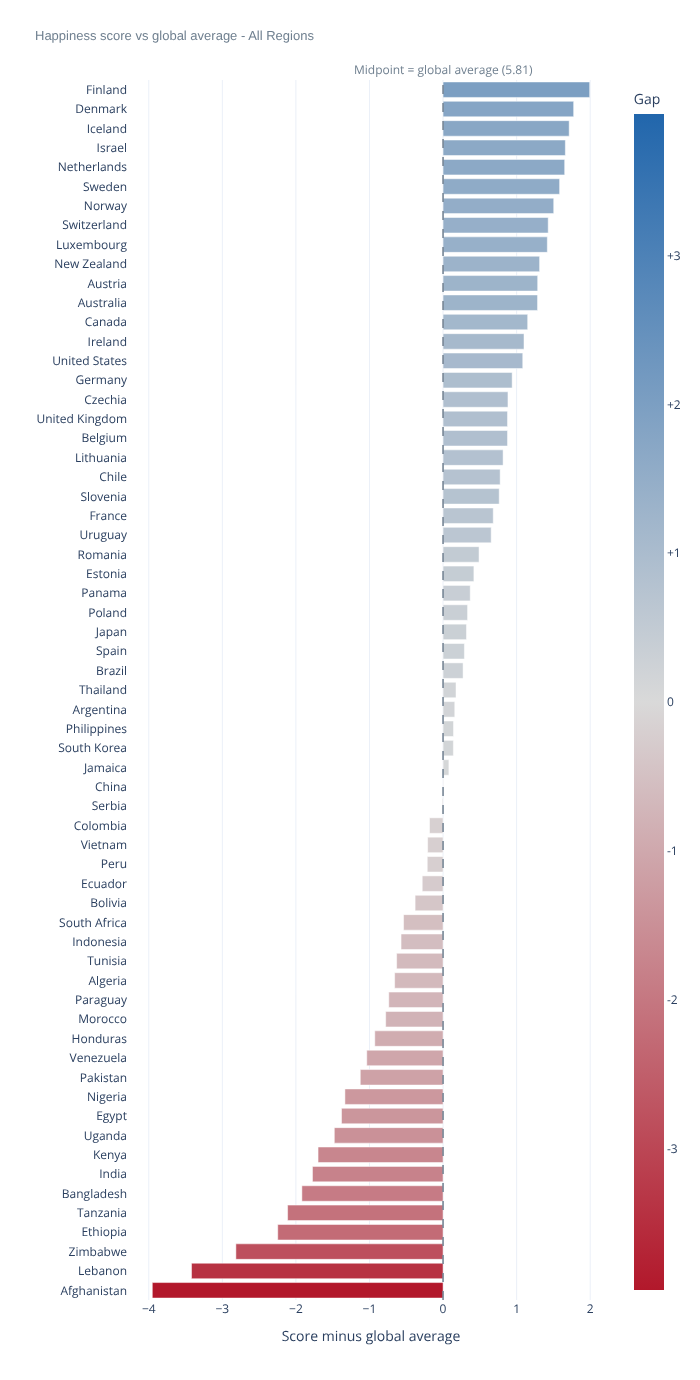

In [9]:
# Preview of the new chart inside the notebook (no Streamlit needed)
import pandas as pd
import plotly.express as px

df = pd.read_csv('../data/world_happiness_2023.csv')
df.columns = ['Country','Region','Score','GDP','Social_Support',
              'Life_Expectancy','Freedom','Generosity','Corruption']

# same variables the dashboard uses (all regions)
selected_region = 'All Regions'
filtered = df

global_avg = df['Score'].mean()
gap = filtered.assign(Gap=filtered['Score'] - global_avg).sort_values('Gap')


# Two hues (red = below, blue = above) with a neutral grey midpoint at 0.
# The range is symmetric so that grey sits exactly in the middle of the colour bar.
limit = float(df['Score'].sub(global_avg).abs().max())
DIVERGING = [[0.0, '#b2182b'], [0.5, '#d9d9d9'], [1.0, '#2166ac']]

fig2 = px.bar(gap, x='Gap', y='Country', orientation='h',
              color='Gap', color_continuous_scale=DIVERGING,
              color_continuous_midpoint=0, range_color=[-limit, limit],
              labels={'Gap': 'Score minus global average', 'Country': ''},
              hover_data={'Score': ':.2f', 'Gap': ':+.2f'},
              template='plotly_white')

# Annotated midpoint: dashed line at 0 with a label
fig2.add_vline(x=0, line_dash='dash', line_color='slategrey', line_width=1.5,
               annotation_text=f'Midpoint = global average ({global_avg:.2f})',
               annotation_position='top', annotation_font=dict(size=12, color='slategrey'))

fig2.update_layout(height=max(400, 20 * len(gap) + 120),
                   title=dict(text=f'Happiness score vs global average - {selected_region}',
                              font=dict(family='Arial', size=13, color='slategrey')),
                   coloraxis_colorbar=dict(title='Gap', tickvals=[-3, -2, -1, 0, 1, 2, 3],
                                           ticktext=['-3', '-2', '-1', '0', '+1', '+2', '+3']),
                   margin=dict(t=80))
fig2.update_xaxes(zeroline=False)

fig2.show()
